In [216]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from pandas import DataFrame, Series

import pims
import trackpy as tp

video = pims.open ("/home/susanta/Downloads/PICT0097.AVI")

print("Number of frames:", len(video))
print ("Frames shape:", video.frame_shape)
fps = getattr(video, 'frame_rate', 15.0)
print(f"Frame rate    : {fps} fps")

Number of frames: 479
Frames shape: (360, 640, 3)
Frame rate    : 15.0 fps


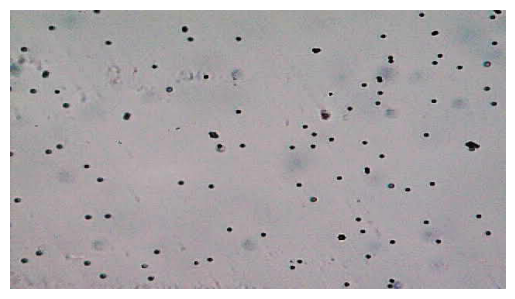

In [217]:
plt.imshow(video[0])
plt.axis('off')
plt.show()

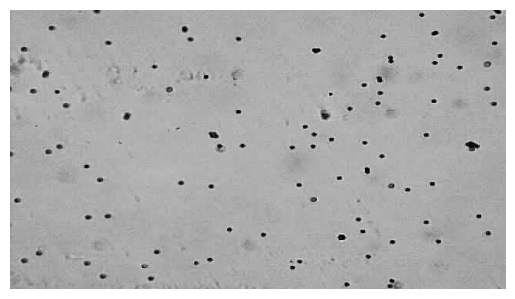

In [218]:
@pims.pipeline
def gray(image):
    if image.ndim == 3:
        return image[:, :, 1]
    return image

frames = gray(video)

plt.imshow(frames[0], cmap='gray')
plt.axis('off')
plt.show()

In [220]:
features = tp.locate(frames[0], diameter=11, minmass=1100, invert=True)
features.head()

,y,x,mass,size,ecc,signal,raw_mass,ep,frame
4,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0
13,9.008884,622.345498,2046.362861,2.183975,0.282615,99.738694,11689.0,0.048864,0
34,22.827969,53.220313,2259.105986,2.322985,0.234079,100.721341,12084.0,0.044285,0
37,24.505342,225.011481,3081.090396,2.521665,0.019220,102.686636,14228.0,0.029354,0
43,29.484370,547.814967,3112.043784,2.615805,0.342761,110.056490,13348.0,0.034068,0


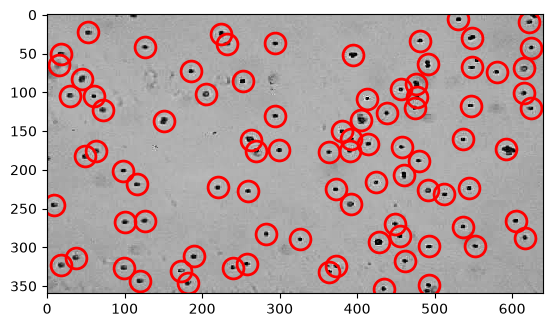

In [222]:
tp.annotate(features, frames[0])
plt.show()

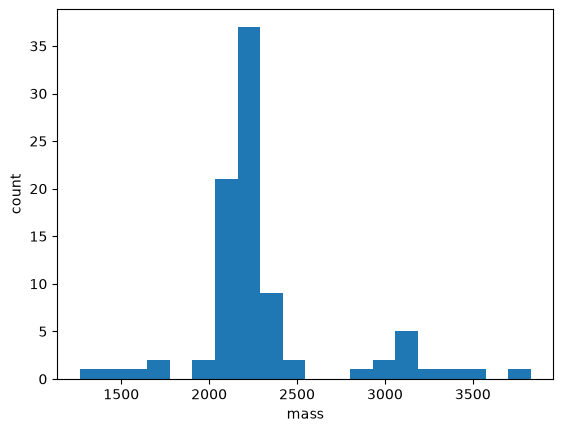

In [223]:
fig, ax = plt.subplots()
ax.hist(features['mass'], bins=20)
ax.set(xlabel='mass', ylabel='count')
plt.show()

In [224]:
features = tp.batch(
    frames,
    diameter=11,
    minmass=1100,
    invert=True,
    processes=1
)

features.head()

Frame 478: 84 features


,y,x,mass,size,ecc,signal,raw_mass,ep,frame
0,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0
1,9.008884,622.345498,2046.362861,2.183975,0.282615,99.738694,11689.0,0.048864,0
2,22.827969,53.220313,2259.105986,2.322985,0.234079,100.721341,12084.0,0.044285,0
3,24.505342,225.011481,3081.090396,2.521665,0.019220,102.686636,14228.0,0.029354,0
4,29.484370,547.814967,3112.043784,2.615805,0.342761,110.056490,13348.0,0.034068,0


## Step 3: Trajectory Linking & Stub Filtering
We link particle coordinates across consecutive frames into trajectories:
- `search_range=5`: Maximum expected displacement (in pixels) between consecutive frames.
- `memory=2`: Allows particles to briefly drop out for up to 2 frames without breaking trajectory continuity.
- `tp.filter_stubs`: Removes short, transient tracks persisting for less than 25 frames.

In [225]:
t = tp.link(features, search_range=5, memory=2)
t.head()

Frame 478: 84 trajectories present.


,y,x,mass,size,ecc,signal,raw_mass,ep,frame,particle
0,5.893607,530.819879,2105.813018,1.997198,0.187624,119.882962,10966.0,0.060271,0,0
1,9.008884,622.345498,2046.362861,2.183975,0.282615,99.738694,11689.0,0.048864,0,1
2,22.827969,53.220313,2259.105986,2.322985,0.234079,100.721341,12084.0,0.044285,0,2
3,24.505342,225.011481,3081.090396,2.521665,0.019220,102.686636,14228.0,0.029354,0,3
4,29.484370,547.814967,3112.043784,2.615805,0.342761,110.056490,13348.0,0.034068,0,4


In [226]:
t1 = tp.filter_stubs(t, 25)

# Compare the number of particles before and after filtering
print(f"Number of particles before filtering: {t['particle'].nunique()}")
print(f"Number of particles after filtering: {t1['particle'].nunique()}")

Number of particles before filtering: 2836
Number of particles after filtering: 612


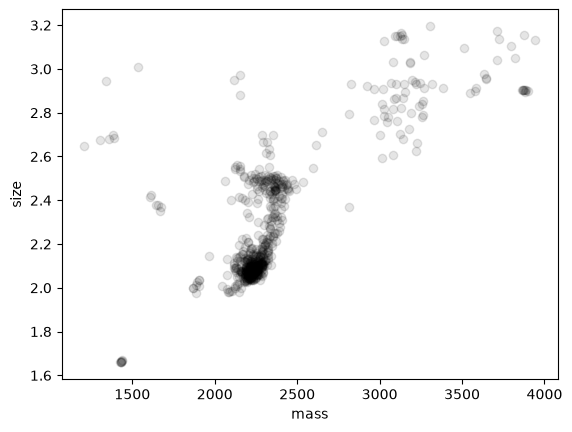

In [227]:
plt.figure()
tp.mass_size(t1.groupby('particle').mean())
plt.show()

Clean, validated trajectories (t2): 527


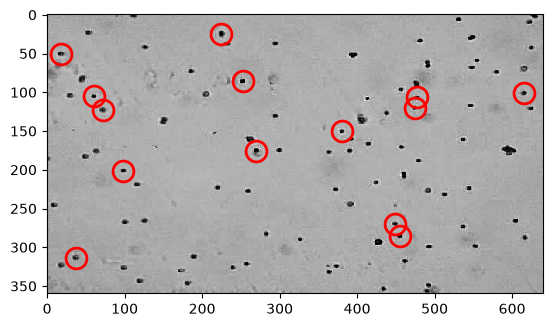

In [248]:
# Filter clean spherical colloidal particles
# t2 = t1[((t1['mass'] > 50) & (t1['size'] < 2.6) 
#          & (t1['ecc'] < 0.3))]
t2 = t1[((t1['mass'] > 1500) & (t1['size'] < 2.6) 
         & (t1['ecc'] < 0.3))]
print(f"Clean, validated trajectories (t2): {t2['particle'].nunique()}")

# Annotate Frame 0 with clean filtered particles
plt.figure()
tp.annotate(t2[t2['frame'] == 0], frames[0])
plt.show()

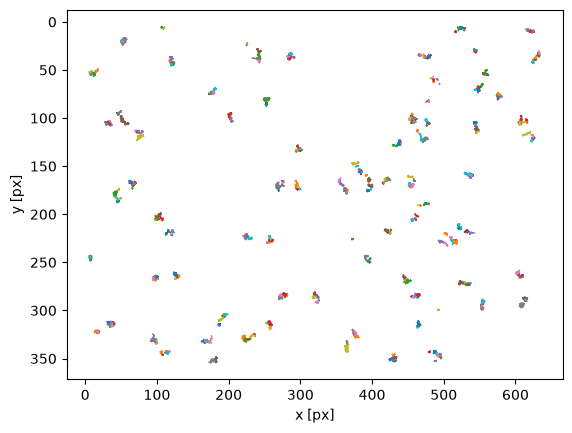

In [249]:
plt.figure()
tp.plot_traj(t2)
plt.show()

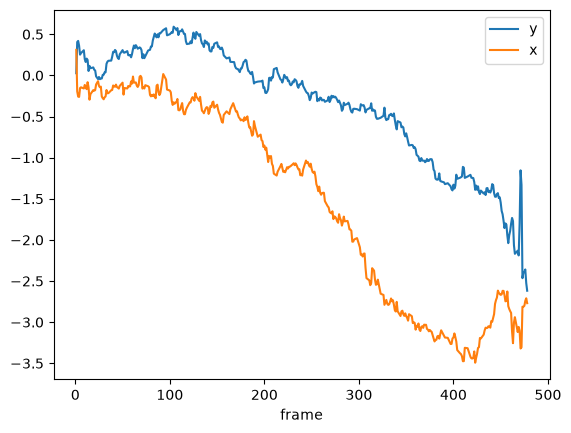

In [250]:
d = tp.compute_drift(t2)
d.plot()
plt.show()

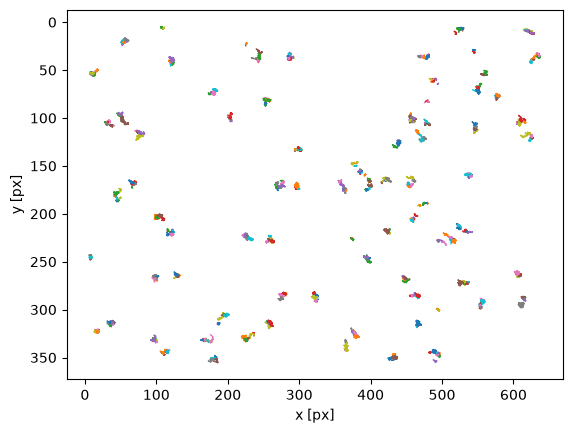

In [251]:
tm = tp.subtract_drift(t2.copy(), d)

ax = tp.plot_traj(tm)
ax.set_title('Drift-subtracted trajectories')
plt.show()

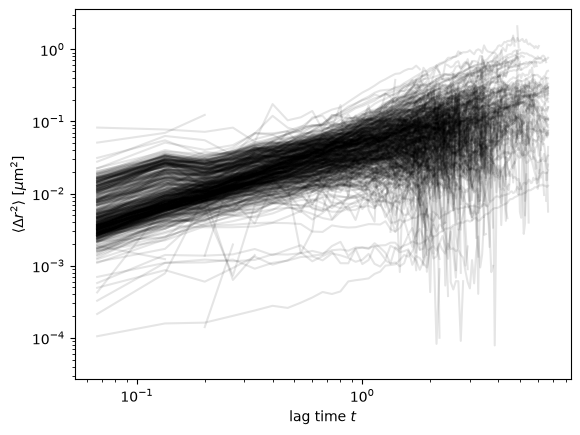

In [252]:
# im = tp.imsd(tm, 100/285., 24)

# Spatial and temporal calibration
fps = 15.0  # Video frame acquisition rate (frames per second)
mpp = 0.12  # Microns per pixel calibration (set to 1.0 for pixel units, or specify calibration e.g., 0.15 um/pixel)
unit_label = r'\mu\mathrm{m}' if mpp != 1.0 else r'\mathrm{pixels}'

# Compute Individual Particle MSDs (IMSD)
im = tp.imsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots()
ax.plot(im.index, im, 'k-', alpha=0.1)
ax.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
       xlabel='lag time $t$')
ax.set_xscale('log')
ax.set_yscale('log')

plt.show()

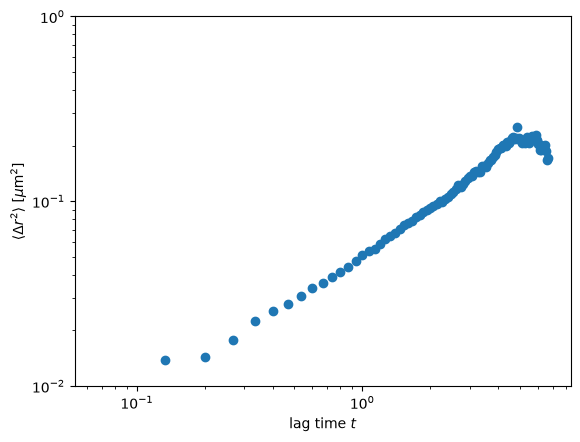

In [276]:
# em = tp.emsd(tm, 100/285., 24)

# Compute Ensemble Mean Squared Displacement (EMSD)
em = tp.emsd(tm, mpp=mpp, fps=fps, max_lagtime=100)

fig, ax = plt.subplots()
ax.plot(em.index, em, 'o')
ax.set_xscale('log')
ax.set_yscale('log')

ax.set(ylabel=r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]',
       xlabel='lag time $t$')
ax.set(ylim=(1e-2, 1));

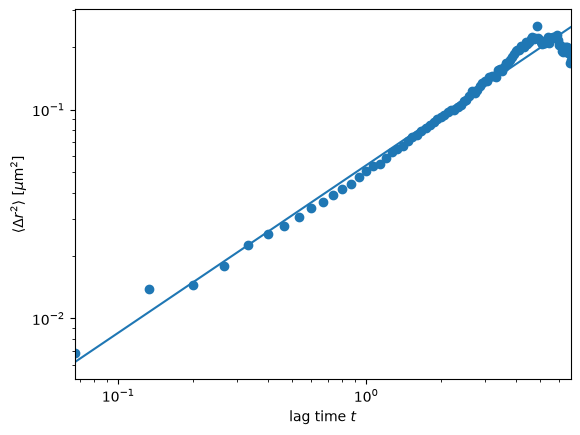

,n,A
msd,0.80272,0.054172


In [285]:
plt.figure()
plt.ylabel(r'$\langle \Delta r^2 \rangle$ [$\mu$m$^2$]')
plt.xlabel('lag time $t$')
tp.utils.fit_powerlaw(em)



In [284]:
# Calculate D, k_B and Avogadro's number


# Physical parameters
T = 298.15                  # Temperature in K (25 °C)
eta = 0.89e-3               # Viscosity of water at 25 °C (Pa.s)
r_um = 2.0                  # Particle radius in micrometers
R = 8.314462618             # Gas constant (J mol^-1 K^-1)


# Select the diffusive (linear) region of the EMSD


t_min = 0.2                 # lower fitting limit (seconds)
t_max = 4.0                 # upper fitting limit (seconds)

time = em.index.values
msd = em.values 


mask = (time >= t_min) & (time <= t_max)

t_fit = time[mask]
msd_fit = msd[mask]


# Linear fit: MSD = 4Dt + intercept


slope, intercept = np.polyfit(t_fit, msd_fit, 1)

# For 2D Brownian motion:
D_um2_s = slope / 4.0

# Convert D from micrometer^2/s to m^2/s
D = D_um2_s * 1e-12



# Stokes-Einstein relation
#
# D = k_B T / (6*pi*eta*r)
#
# Therefore:
# k_B = 6*pi*eta*r*D/T


r = r_um * 1e-6              # radius in meters

k_B = (6 * np.pi * eta * r * D) / T


# Avogadro's number
#
# R = N_A * k_B


N_A = R / k_B


# Print results


print(f"Temperature, T       = {T:.2f} K")
print(f"Water viscosity, eta = {eta:.3e} Pa.s")
print(f"Particle radius, r   = {r_um:.2f} µm")
print(f"mpp                  = {mpp:.4f} µm/pixel")

print("----------------------------------------")
print(f"MSD slope            = {slope:.6f} µm²/s")
print(f"Diffusion coefficient D = {D_um2_s:.6f} µm²/s")
print(f"Diffusion coefficient D = {D:.6e} m²/s")

print("----------------------------------------")
print(f"Boltzmann constant k_B = {k_B:.6e} J/K")
print(f"Avogadro number N_A    = {N_A:.6e} mol⁻¹")


Temperature, T       = 298.15 K
Water viscosity, eta = 8.900e-04 Pa.s
Particle radius, r   = 2.00 µm
mpp                  = 0.1200 µm/pixel
----------------------------------------
MSD slope            = 0.043250 µm²/s
Diffusion coefficient D = 0.010812 µm²/s
Diffusion coefficient D = 1.081245e-14 m²/s
----------------------------------------
Boltzmann constant k_B = 1.216776e-24 J/K
Avogadro number N_A    = 6.833193e+24 mol⁻¹


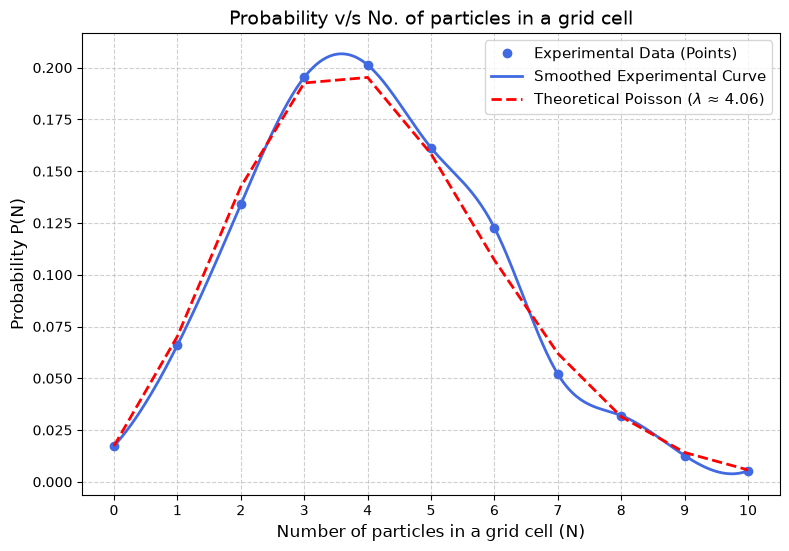

In [283]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
from scipy.interpolate import make_interp_spline
from collections import Counter

# --- 1. Load your grid count data ---
# Replace 'grid_counts' with your actual 1D array/list of particle counts for all cells across all 15 frames.
# For demonstration, I am simulating data that follows a Poisson distribution with mean ~4.1.
np.random.seed(42)
grid_counts = np.random.poisson(lam=4.1, size=1500) 

total_grid_cells = len(grid_counts)

# --- 2. Calculate Frequencies ---
# Count how many grid cells have exactly N particles
count_freq = Counter(grid_counts)

# Sort the N values (0, 1, 2, 3...)
N_values = np.array(sorted(count_freq.keys()))
grids_with_N = np.array([count_freq[N] for N in N_values])

# --- 3. Calculate Probabilities ---
# Standard probability (matches standard Poisson curve)
P_N = grids_with_N / total_grid_cells

# If you specifically need to use the exact formula from the text, uncomment the line below:
# P_N = (N_values * grids_with_N) / total_grid_cells

# --- 4. Smooth the Data Curve ---
# Generate dense x values for a smooth curve
x_smooth = np.linspace(N_values.min(), N_values.max(), 300)

# Use spline interpolation to smooth the experimental data (k=3 means cubic spline)
spline = make_interp_spline(N_values, P_N, k=3)
P_smooth = spline(x_smooth)

# Clip to 0 to ensure the smoothing artifact doesn't dip into negative probabilities
P_smooth = np.clip(P_smooth, 0, None)

# --- 5. Generate Theoretical Poisson Curve ---
# Calculate the actual mean (lambda) from your data
mean_lambda = np.mean(grid_counts) 

# Generate the theoretical Poisson PMF
poisson_theoretical = poisson.pmf(N_values, mu=mean_lambda)

# --- 6. Plotting ---
plt.figure(figsize=(9, 6))

# Plot raw experimental data points
plt.plot(N_values, P_N, 'o', color='royalblue', label='Experimental Data (Points)')

# Plot smoothed experimental curve
plt.plot(x_smooth, P_smooth, '-', color='royalblue', linewidth=2, label='Smoothed Experimental Curve')

# Plot theoretical Poisson distribution
plt.plot(N_values, poisson_theoretical, 'r--', linewidth=2, label=f'Theoretical Poisson ($\\lambda$ ≈ {mean_lambda:.2f})')

# Formatting the plot
plt.xlabel('Number of particles in a grid cell (N)', fontsize=12)
plt.ylabel('Probability P(N)', fontsize=12)
plt.title('Probability v/s No. of particles in a grid cell', fontsize=14)
plt.xticks(N_values) # Ensure x-axis ticks match discrete particle counts
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()